# v10 interpretability, part 1: H0 record · H6 is the self real? · H1 is it something known? (GPU 0, no training)
**One language: English → Hindi** (FLORES dev, 997 sentences, teacher forcing).

Models: Hindi-only phase 45 · continual distant phase 10 and 40 (both Hindi phases) · an **untrained model** (random weights) as the control.

- **H6:** size of the largest co-firing group as the threshold goes 0.05 → 0.5, for the real activity vs 3 nulls (randomly rotated neurons, shuffled tokens, a random graph with the same number of links).
- **H1:** per-neuron scores for known neuron families (entropy neurons, token-frequency neurons, massive activations, universal-neuron signs, position/token neurons, language-specific neurons); are self neurons over-represented?

Results: `analysis/v10/interp/` (report.txt + figures). Takes roughly 10–20 min per model.

In [1]:
import os, sys, glob, json, time, subprocess
os.environ["HF_HUB_DISABLE_XET"] = "1"
GPU = "0"
REPO = "/workspace/shreshth"; os.chdir(REPO); sys.path.insert(0, REPO)
from IPython.display import Image, display
from huggingface_hub import HfApi, hf_hub_download
for attempt in range(5):
    try:
        api = HfApi(); HF_REPO = api.whoami()["name"] + "/cml-lang-self-checkpoints"; FILES = api.list_repo_files(HF_REPO); break
    except Exception as e:
        print("HF retry", attempt, type(e).__name__); time.sleep(10)

def get(run, phases):
    for ph in phases:
        if glob.glob(f"runs/{run}/ckpt/p{ph:03d}_*.pt"):
            continue
        name = [f for f in FILES if f.startswith(f"{run}/ckpt/p{ph:03d}_")]
        if name:
            hf_hub_download(HF_REPO, name[0], local_dir="runs")
        else:
            print("missing (not here, not on HF):", run, ph)

def last_phase(run):
    phs = [int(os.path.basename(f)[1:4]) for f in FILES if f.startswith(f"{run}/ckpt/p")]
    phs += [int(os.path.basename(f)[1:4]) for f in glob.glob(f"runs/{run}/ckpt/p*.pt")]
    return max(phs)


def run(*cmd):
    env = {**os.environ, "CML_LANGSET": "distant"}
    p = subprocess.Popen([sys.executable, "-u", "interp_v10.py", "--gpu", GPU, *cmd], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env)
    for line in p.stdout:
        print(line, end="")
    p.wait(); print("exit code", p.returncode)

MODELS = [("hindi45", "v4b_only_hi_s0", 45), ("cont40", "v4b_continual_s0", 40), ("cont10", "v4b_continual_s0", 10)]
for _, r, ph in MODELS:
    get(r, [ph])
need = ["data/en-hi/train.jsonl", "tokenizer_v4/spm.model"] + [f"data/flores/dev.{l}.jsonl" for l in ["en", "hi", "zh", "ar"]]
miss = [f for f in need if not os.path.exists(f)]
print("all there" if not miss else f"MISSING: {miss}")

p045_hi.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

p040_hi.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

p010_hi.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

all there


In [2]:
# old results from an earlier call are appended to, so start clean
import shutil; shutil.rmtree("analysis/v10/interp", ignore_errors=True)
for n, r, ph in MODELS:
    run("--model", f"{n}={r}:{ph}")
run("--model", "random=random")

model hindi45 = v4b_only_hi_s0:45 | 67M parameters
token counts from 200k training pairs in 5s
H0 recorded 31,993 encoder (English) and 36,524 decoder (Hindi) tokens in 7s | Hindi loss inf, top-1 correct 63.4%
  enc0: self at tau 0.2 = 1138 of 2560 working neurons
  enc1: self at tau 0.2 = 799 of 2560 working neurons
  enc2: self at tau 0.2 = 815 of 2560 working neurons
  enc3: self at tau 0.2 = 988 of 2560 working neurons
  dec0: self at tau 0.2 = 1414 of 2560 working neurons
  dec1: self at tau 0.2 = 963 of 2560 working neurons
  dec2: self at tau 0.2 = 980 of 2560 working neurons
  dec3: self at tau 0.2 = 1538 of 2560 working neurons
H6 done in 28s | largest group at tau 0.2 (avg of 8 layers): real 42.2% | rotated 26.7% | same-density random graph 82.8% | shuffled 0.0%
  enc0 scored
  enc1 scored
  enc2 scored
  enc3 scored
  dec0 scored
  dec1 scored
  dec2 scored
  dec3 scored
H1 done in 28s (null directions = bottom 13 of 640)
done
exit code 0
model cont40 = v4b_continual_s0:40 |

=== H6: is the self real? size of the largest co-firing group (% of working neurons), average of the 8 layers ===
tau                                 0.05   0.10   0.15   0.20  0.25  0.30  0.40  0.50
model   condition                                                                    
cont10  real                       100.0   99.3   87.7   58.2  32.2  13.8   2.0   0.7
        rotated                    100.0   98.6   60.5   27.3  12.3   5.8   1.2   0.2
        same-density random graph  100.0  100.0   99.8   92.8  51.2  17.3   0.4   0.2
        shuffled                     0.2    0.1    0.0    0.0   0.0   0.0   0.0   0.0
cont40  real                       100.0   98.9   85.4   53.8  25.7   9.6   1.5   0.6
        rotated                    100.0   92.0   48.8   22.7  11.9   7.0   2.7   1.1
        same-density random graph  100.0  100.0   99.2   85.6  35.8  13.2   0.4   0.1
        shuffled                     0.5    0.1    0.0    0.0   0.0   0.0   0.0   0.0
hindi45 real              

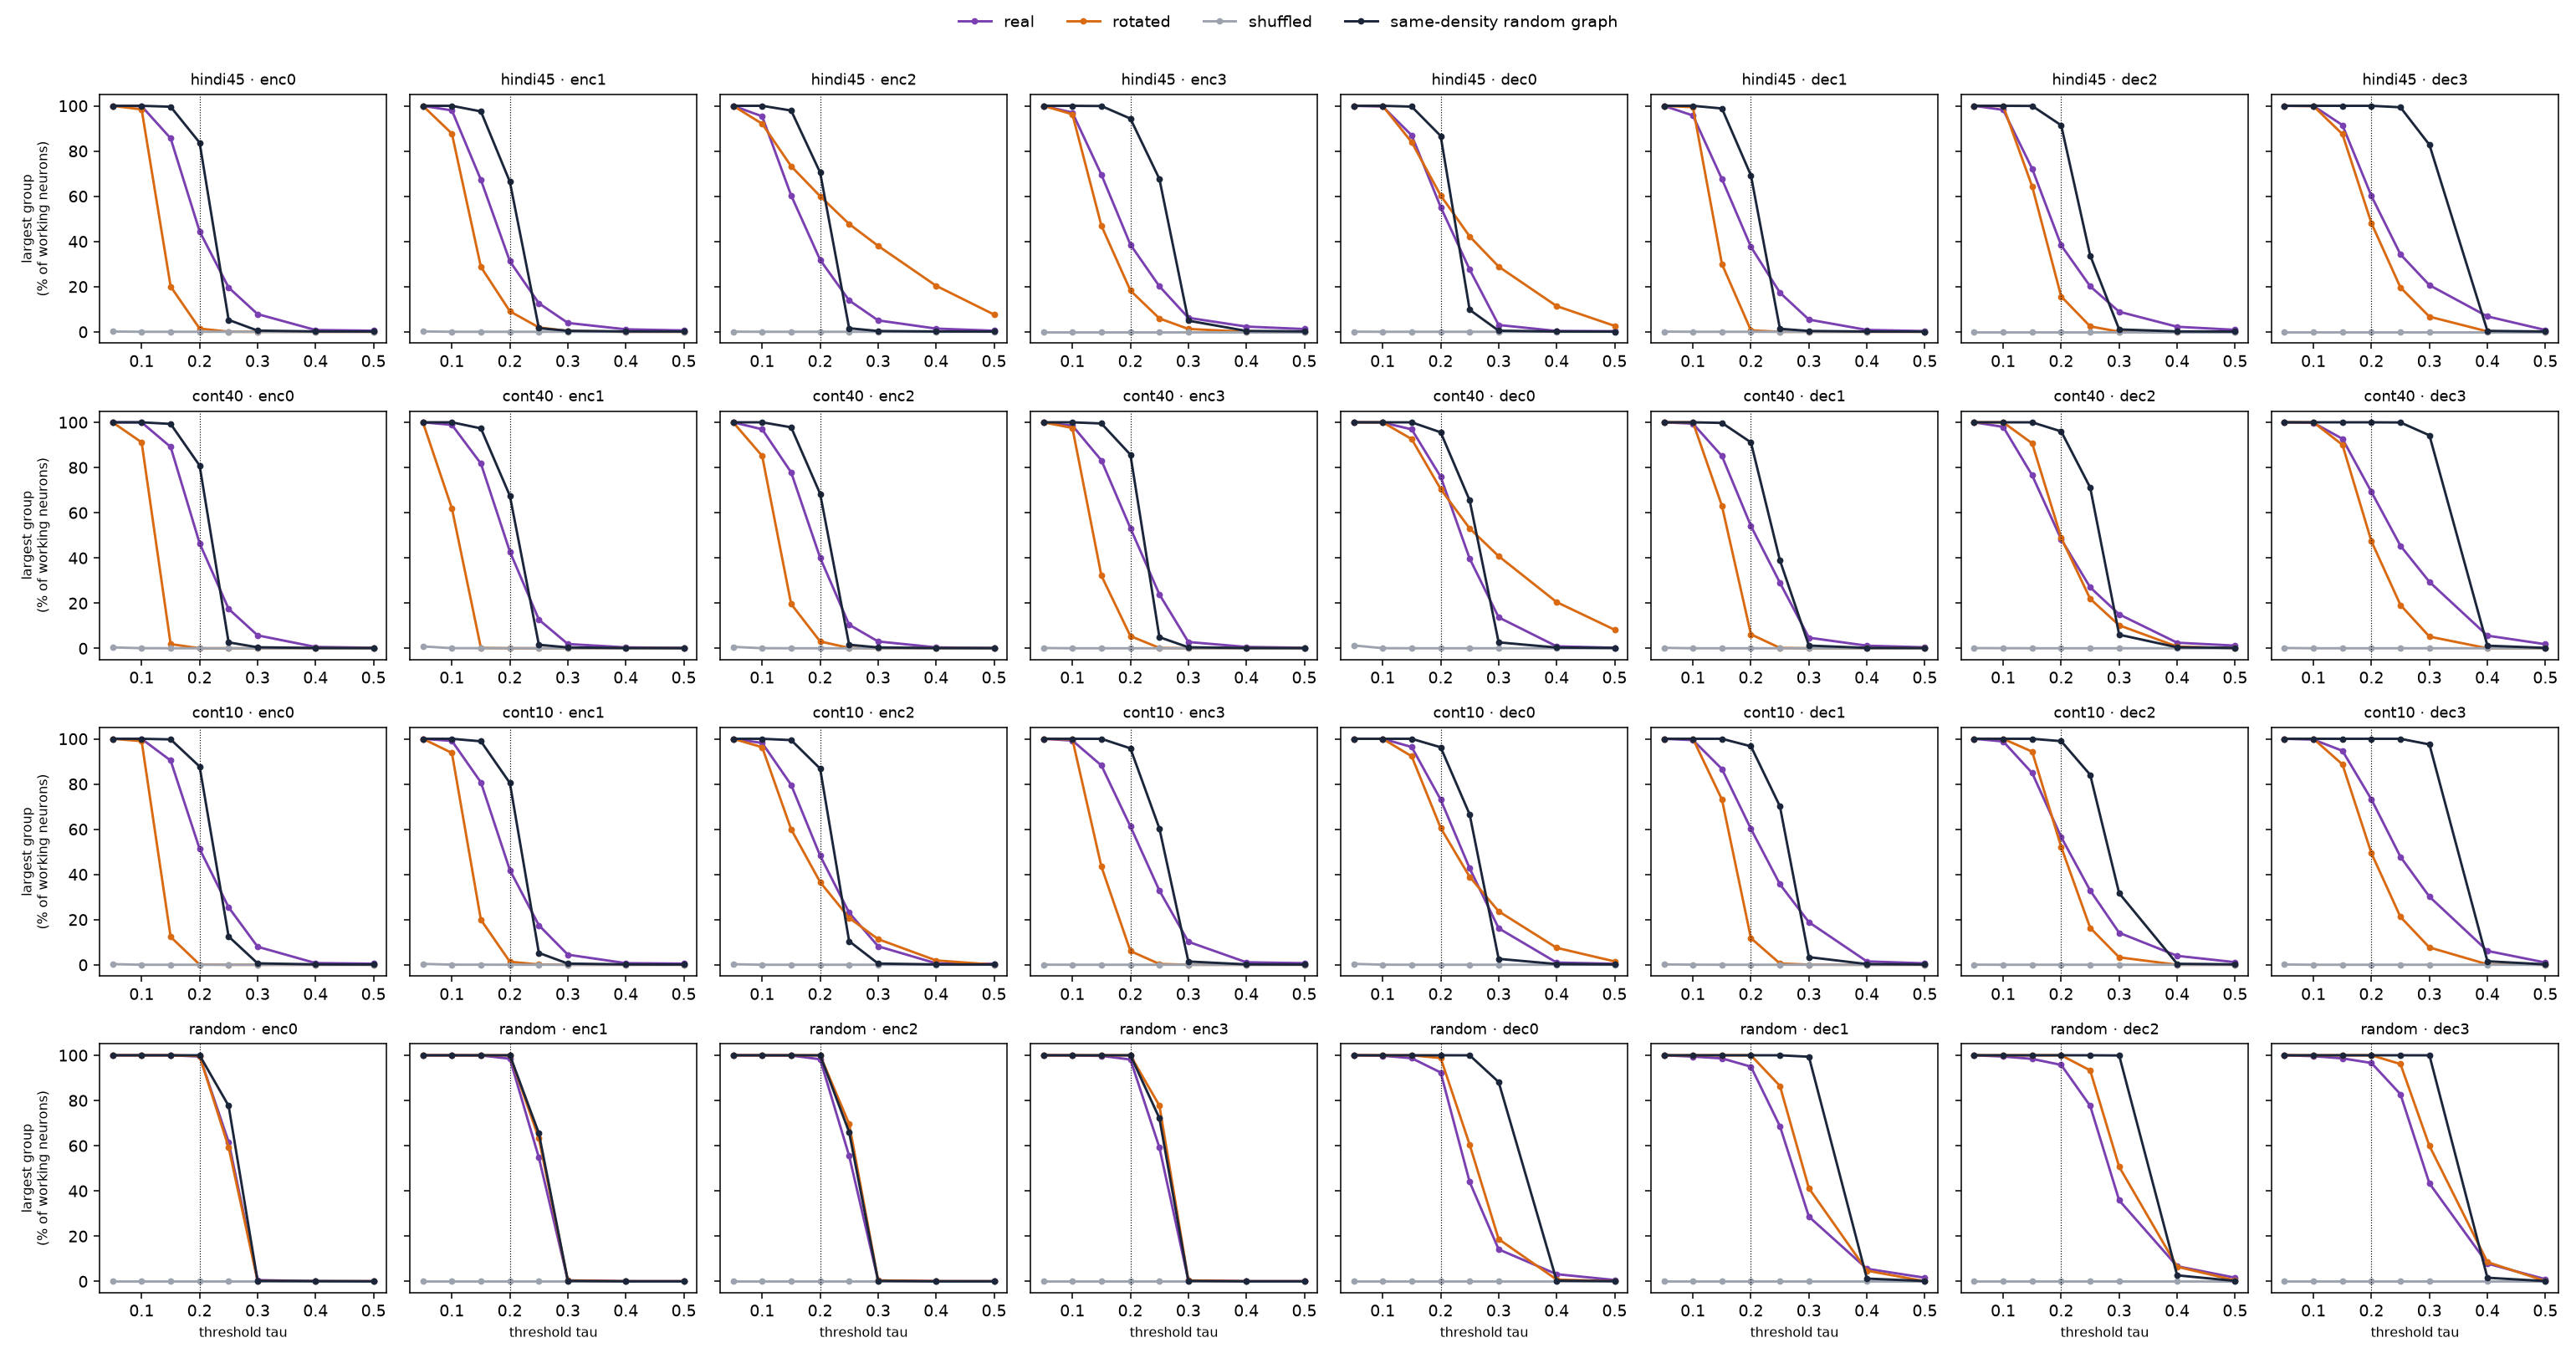

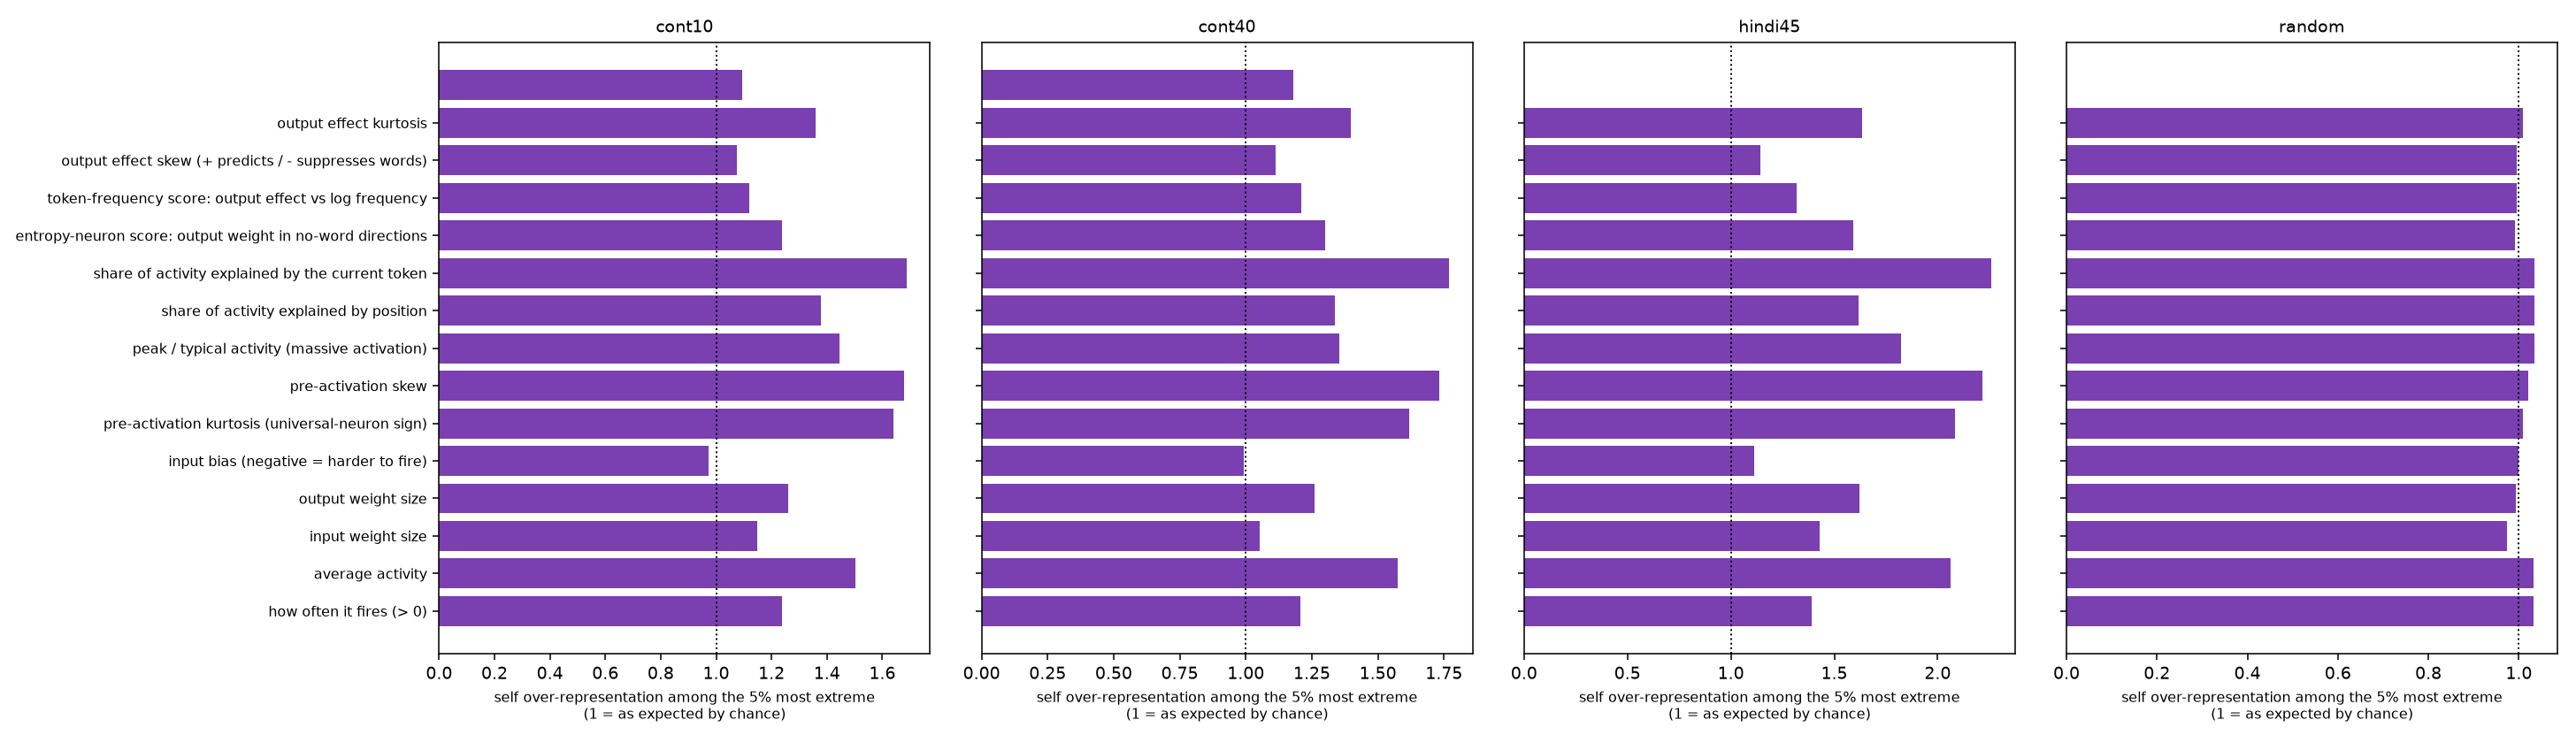

In [3]:
subprocess.run([sys.executable, "interp_v10.py", "--summarize"])
for f in ["h6_giant_vs_tau.png", "h1_enrichment.png"]:
    display(Image(f"analysis/v10/interp/{f}"))